In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv()

db_password = os.getenv("DB_PASSWORD")

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password=db_password,
    host="localhost",
    port=5432,
    database="intelligent_business_analytics"
)

engine = create_engine(connection_url)

print("PostgreSQL connection configured successfully.")

PostgreSQL connection configured successfully.


In [6]:
query = """
SELECT
    order_date::DATE AS date,
    ROUND(SUM(final_amount), 2) AS daily_revenue,
    COUNT(DISTINCT order_id) AS daily_orders,
    COUNT(DISTINCT customer_id) AS daily_customers
FROM ecommerce.orders
WHERE order_date IS NOT NULL
GROUP BY order_date::DATE
ORDER BY date;
"""

df = pd.read_sql(query, engine)

print("Dataset loaded successfully.")
print(f"Rows: {len(df)}")
print(f"Columns: {len(df.columns)}")

df.head()

Dataset loaded successfully.
Rows: 1096
Columns: 4


,date,daily_revenue,daily_orders,daily_customers
0,2023-01-01,34458.27,1,1
1,2023-01-02,1744.73,1,1
2,2023-01-03,294.78,1,1
3,2023-01-04,36552.81,1,1
4,2023-01-05,77644.93,3,3


In [7]:
# Basic dataset validation

print("Dataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Dates:")
print(df["date"].duplicated().sum())

print("\nDate Range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

Dataset Shape:
(1096, 4)

Data Types:
date                object
daily_revenue      float64
daily_orders         int64
daily_customers      int64
dtype: object

Missing Values:
date               0
daily_revenue      0
daily_orders       0
daily_customers    0
dtype: int64

Duplicate Dates:
0

Date Range:
Start: 2023-01-01
End: 2025-12-31


In [8]:
# Convert date column to datetime

df["date"] = pd.to_datetime(df["date"])
print("Date column converted successfully.")
print(df.dtypes)

Date column converted successfully.
date               datetime64[s]
daily_revenue            float64
daily_orders               int64
daily_customers            int64
dtype: object


In [9]:
# Check for missing dates in the time series

expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(df["date"])

print("Expected days:", len(expected_dates))
print("Actual records:", len(df))
print("Missing days:", len(missing_dates))

if len(missing_dates) == 0:
    print("✓ No missing dates. The time series is continuous.")
else:
    print("Missing dates:")
    print(missing_dates)

Expected days: 1096
Actual records: 1096
Missing days: 0
✓ No missing dates. The time series is continuous.


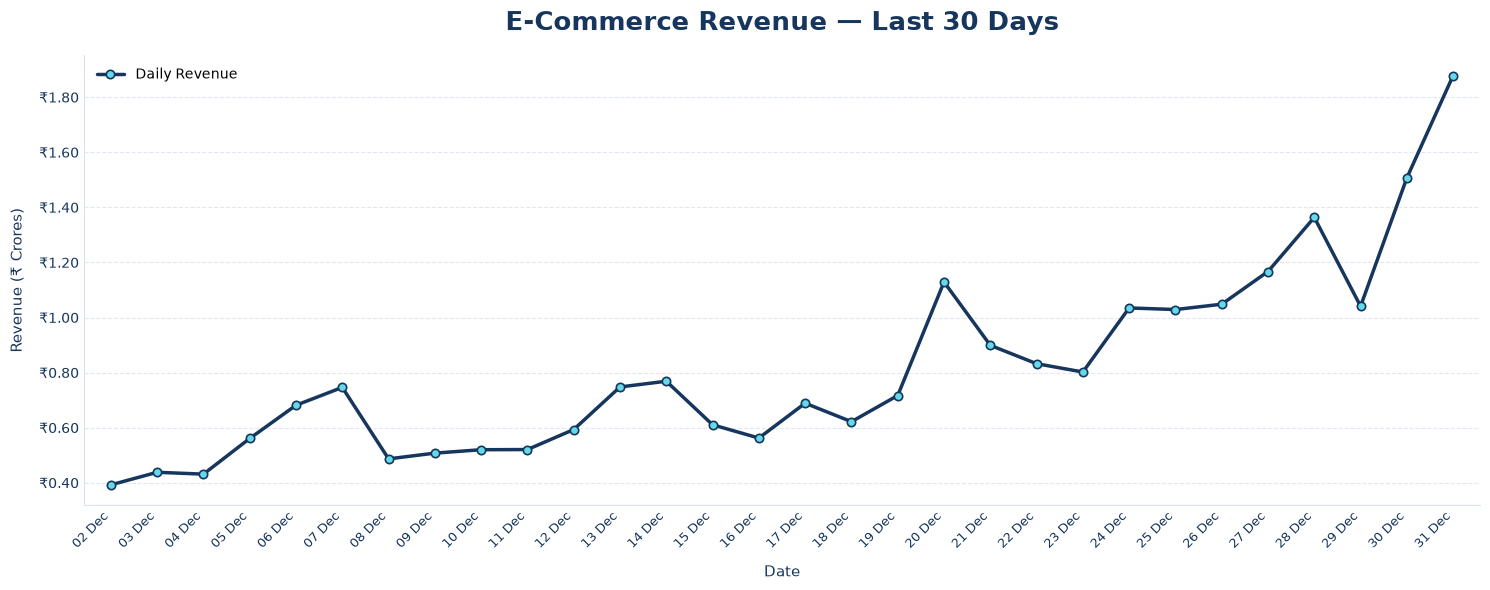

In [ ]:
# Last 30 days revenue trend 

last_30 = df.tail(30).copy()

# Power BI-inspired colors
NAVY = "#17365D"
LIGHT_BLUE = "#64D9E8"
GRID = "#D9E2F3"
TEXT = "#17365D"
BACKGROUND = "#FFFFFF"

fig, ax = plt.subplots(figsize=(15, 6))

# Background
fig.patch.set_facecolor(BACKGROUND)
ax.set_facecolor(BACKGROUND)

# Main revenue line
ax.plot(
    last_30["date"],
    last_30["daily_revenue"],
    color=NAVY,
    marker="o",
    markerfacecolor=LIGHT_BLUE,
    markeredgecolor=NAVY,
    markeredgewidth=1.2,
    linewidth=2.5,
    markersize=6,
    solid_capstyle="round",
    label="Daily Revenue"
)

# Title
ax.set_title(
    "E-Commerce Revenue — Last 30 Days",
    fontsize=19,
    fontweight="bold",
    color=TEXT,
    pad=18
)

# Axis labels
ax.set_xlabel(
    "Date",
    fontsize=11,
    color=TEXT,
    labelpad=10
)

ax.set_ylabel(
    "Revenue (₹ Crores)",
    fontsize=11,
    color=TEXT,
    labelpad=10
)

# Revenue in Crores
from matplotlib.ticker import FuncFormatter

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x/1e7:.2f}")
)

# Show every date
ax.set_xticks(last_30["date"])

ax.set_xticklabels(
    last_30["date"].dt.strftime("%d %b"),
    rotation=45,
    ha="right",
    fontsize=9
)

# Professional grid
ax.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(
    axis="x",
    visible=False
)

# Clean Power BI-style borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

# Tick styling
ax.tick_params(
    axis="both",
    colors=TEXT,
    length=0
)

# Legend
ax.legend(
    loc="upper left",
    frameon=False,
    fontsize=10
)

# Slight padding around the data
ax.margins(x=0.02)

plt.tight_layout()
plt.show()

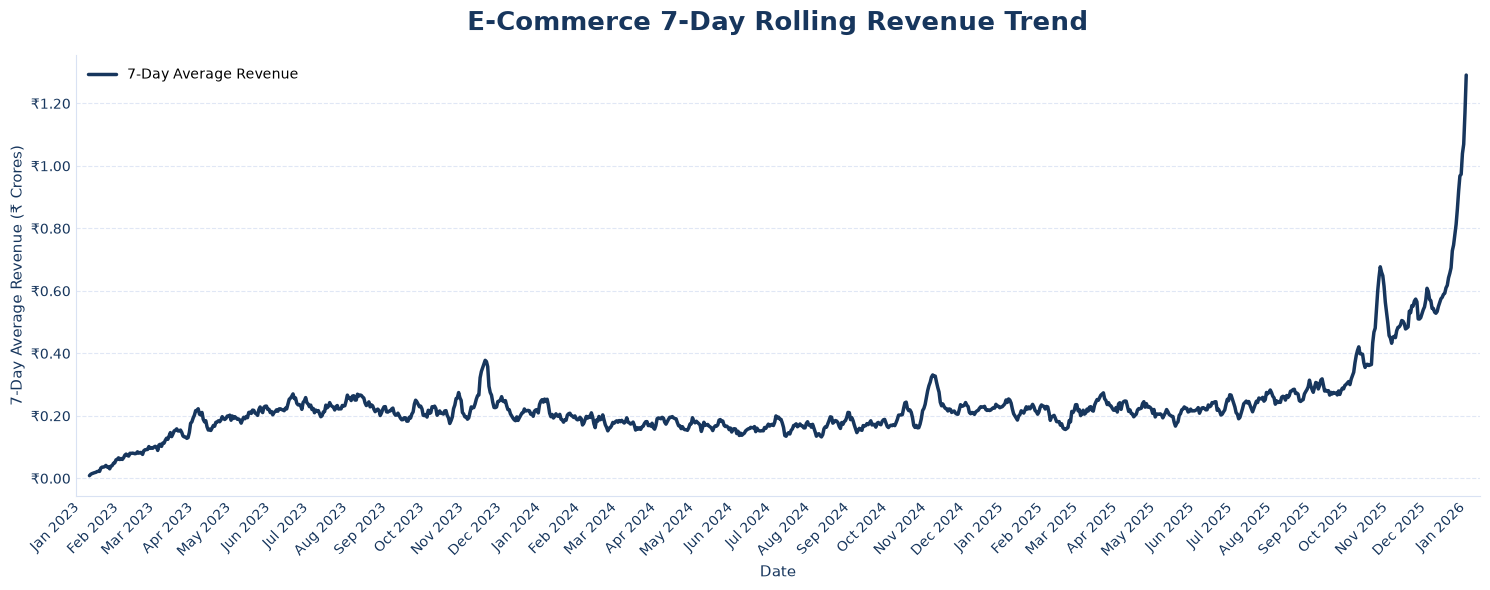

In [ ]:
# 7-Day Rolling Revenue Trend 

df["revenue_7d_avg"] = (
    df["daily_revenue"]
    .rolling(window=7)
    .mean()
)

plot_df = df.dropna(subset=["revenue_7d_avg"]).copy()

# Convert revenue to Crores
plot_df["revenue_7d_avg_crores"] = (
    plot_df["revenue_7d_avg"] / 1e7
)

# Power BI colors
NAVY = "#17365D"
GRID = "#D9E2F3"

fig, ax = plt.subplots(figsize=(15, 6))

# 7-day rolling average
ax.plot(
    plot_df["date"],
    plot_df["revenue_7d_avg_crores"],
    color=NAVY,
    linewidth=2.5,
    solid_capstyle="round",
    label="7-Day Average Revenue"
)

# Title
ax.set_title(
    "E-Commerce 7-Day Rolling Revenue Trend",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

# Axis labels
ax.set_xlabel(
    "Date",
    fontsize=11,
    color=NAVY
)

ax.set_ylabel(
    "7-Day Average Revenue (₹ Crores)",
    fontsize=11,
    color=NAVY
)

# X-axis
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(
    rotation=45,
    ha="right"
)

# Y-axis — now already in Crores
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:.2f}")
)

# Grid
ax.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(
    axis="x",
    visible=False
)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

# Clean ticks
ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

ax.legend(
    loc="upper left",
    frameon=False
)

ax.margins(x=0.01)

plt.tight_layout()
plt.show()

In [20]:
# Weekly Revenue Pattern

df["day_of_week"] = df["date"].dt.day_name()

# Keep weekdays in correct order
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_revenue = (
    df.groupby("day_of_week")["daily_revenue"]
    .mean()
    .reindex(day_order)
)

# Convert to Crores
weekly_revenue_crores = weekly_revenue / 1e7

print("Average Daily Revenue by Day of Week:")
print(weekly_revenue_crores.round(2))

Average Daily Revenue by Day of Week:
day_of_week
Monday      0.22
Tuesday     0.22
Wednesday   0.23
Thursday    0.22
Friday      0.22
Saturday    0.27
Sunday      0.27
Name: daily_revenue, dtype: float64


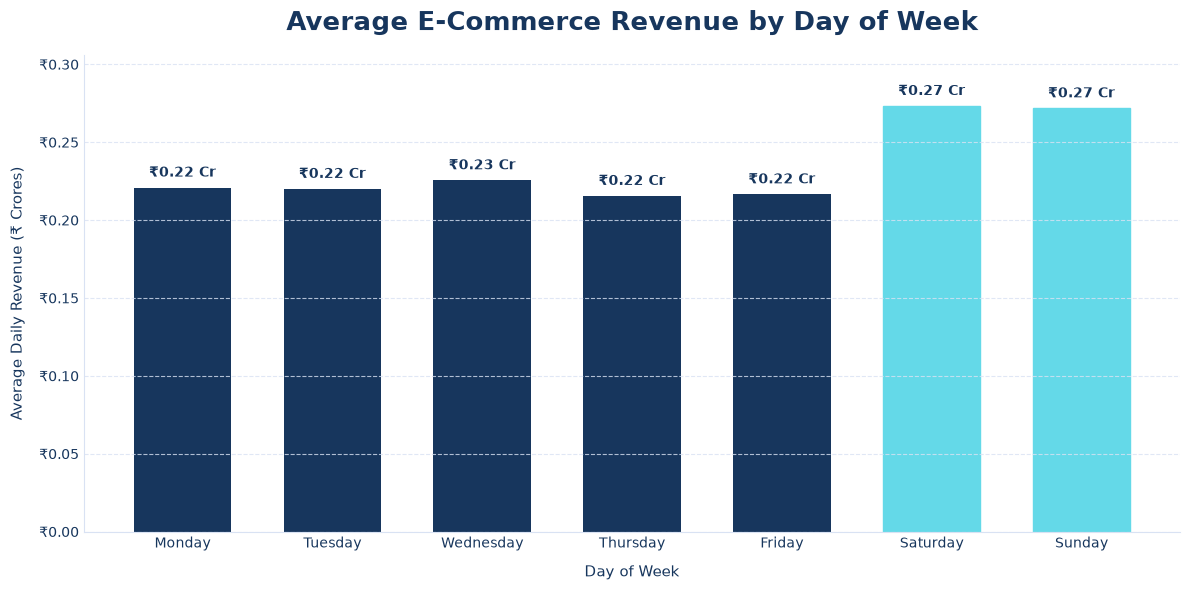

In [21]:
# Average Revenue by Day of Week — Professional Power BI Style

from matplotlib.ticker import FuncFormatter

# Power BI colors
NAVY = "#17365D"
CYAN = "#64D9E8"
GRID = "#D9E2F3"

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    weekly_revenue_crores.index,
    weekly_revenue_crores.values,
    width=0.65,
    color=NAVY
)

# Highlight weekend
for i, day in enumerate(weekly_revenue_crores.index):
    if day in ["Saturday", "Sunday"]:
        bars[i].set_color(CYAN)

# Title
ax.set_title(
    "Average E-Commerce Revenue by Day of Week",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

ax.set_xlabel(
    "Day of Week",
    fontsize=11,
    color=NAVY,
    labelpad=10
)

ax.set_ylabel(
    "Average Daily Revenue (₹ Crores)",
    fontsize=11,
    color=NAVY,
    labelpad=10
)

# Y-axis formatting
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:.2f}")
)

# Grid
ax.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis="x", visible=False)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

# Add values above bars
for bar, value in zip(bars, weekly_revenue_crores.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"₹{value:.2f} Cr",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=NAVY
    )

ax.margins(y=0.12)

plt.tight_layout()
plt.show()

In [22]:
# Monthly Seasonality Analysis

df["month"] = df["date"].dt.month

monthly_revenue = (
    df.groupby("month")["daily_revenue"]
    .mean()
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_revenue.index = [
    month_names[i - 1] for i in monthly_revenue.index
]

monthly_revenue_crores = monthly_revenue / 1e7

print("Average Daily Revenue by Month:")
print(monthly_revenue_crores.round(2))

Average Daily Revenue by Month:
Jan   0.15
Feb   0.15
Mar   0.19
Apr   0.19
May   0.19
Jun   0.21
Jul   0.21
Aug   0.23
Sep   0.22
Oct   0.30
Nov   0.35
Dec   0.41
Name: daily_revenue, dtype: float64


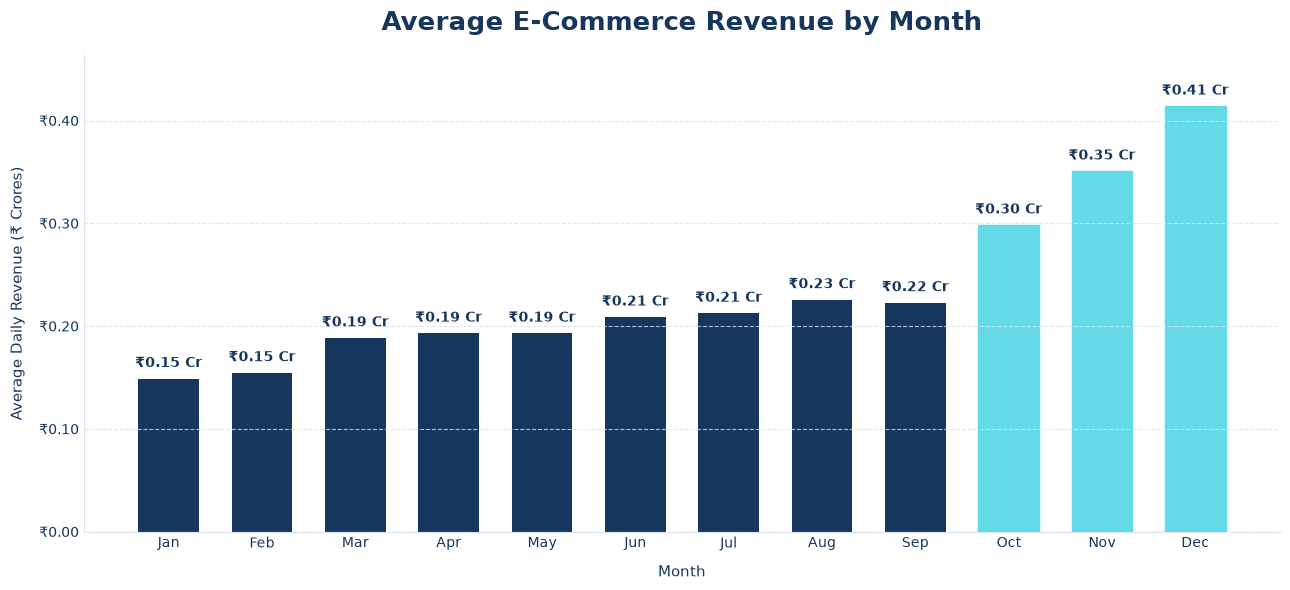

In [23]:
# Average Revenue by Month 

from matplotlib.ticker import FuncFormatter

# Power BI colors
NAVY = "#17365D"
CYAN = "#64D9E8"
GRID = "#D9E2F3"

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.bar(
    monthly_revenue_crores.index,
    monthly_revenue_crores.values,
    width=0.65,
    color=NAVY
)

# Highlight Q4
for i, month in enumerate(monthly_revenue_crores.index):
    if month in ["Oct", "Nov", "Dec"]:
        bars[i].set_color(CYAN)

# Title
ax.set_title(
    "Average E-Commerce Revenue by Month",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

ax.set_xlabel(
    "Month",
    fontsize=11,
    color=NAVY,
    labelpad=10
)

ax.set_ylabel(
    "Average Daily Revenue (₹ Crores)",
    fontsize=11,
    color=NAVY,
    labelpad=10
)

# Y-axis
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:.2f}")
)

# Grid
ax.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis="x", visible=False)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

# Values above bars
for bar, value in zip(bars, monthly_revenue_crores.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f"₹{value:.2f} Cr",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=NAVY
    )

ax.margins(y=0.12)

plt.tight_layout()
plt.show()

In [24]:
# Revenue Distribution & Outlier Analysis

Q1 = df["daily_revenue"].quantile(0.25)
Q3 = df["daily_revenue"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["daily_revenue"] < lower_bound) |
    (df["daily_revenue"] > upper_bound)
].copy()

print("Revenue Outlier Analysis")
print("-" * 40)

print(f"Q1: ₹{Q1 / 1e7:.2f} Cr")
print(f"Q3: ₹{Q3 / 1e7:.2f} Cr")
print(f"IQR: ₹{IQR / 1e7:.2f} Cr")

print(f"\nLower Bound: ₹{lower_bound / 1e7:.2f} Cr")
print(f"Upper Bound: ₹{upper_bound / 1e7:.2f} Cr")

print(f"\nTotal Days: {len(df)}")
print(f"Outlier Days: {len(outliers)}")
print(
    f"Outlier Percentage: "
    f"{(len(outliers) / len(df)) * 100:.2f}%"
)

print("\nHighest Revenue Days:")
print(
    outliers[
        ["date", "daily_revenue"]
    ]
    .sort_values("daily_revenue", ascending=False)
    .head(10)
)

Revenue Outlier Analysis
----------------------------------------
Q1: ₹0.16 Cr
Q3: ₹0.26 Cr
IQR: ₹0.10 Cr

Lower Bound: ₹0.01 Cr
Upper Bound: ₹0.41 Cr

Total Days: 1096
Outlier Days: 79
Outlier Percentage: 7.21%

Highest Revenue Days:
           date  daily_revenue
1095 2025-12-31    18786847.82
1094 2025-12-30    15071415.15
1092 2025-12-28    13635132.50
1091 2025-12-27    11670573.35
1084 2025-12-20    11290032.65
1090 2025-12-26    10482848.95
1093 2025-12-29    10409140.13
1088 2025-12-24    10347807.11
1089 2025-12-25    10289509.05
1085 2025-12-21     8990216.57


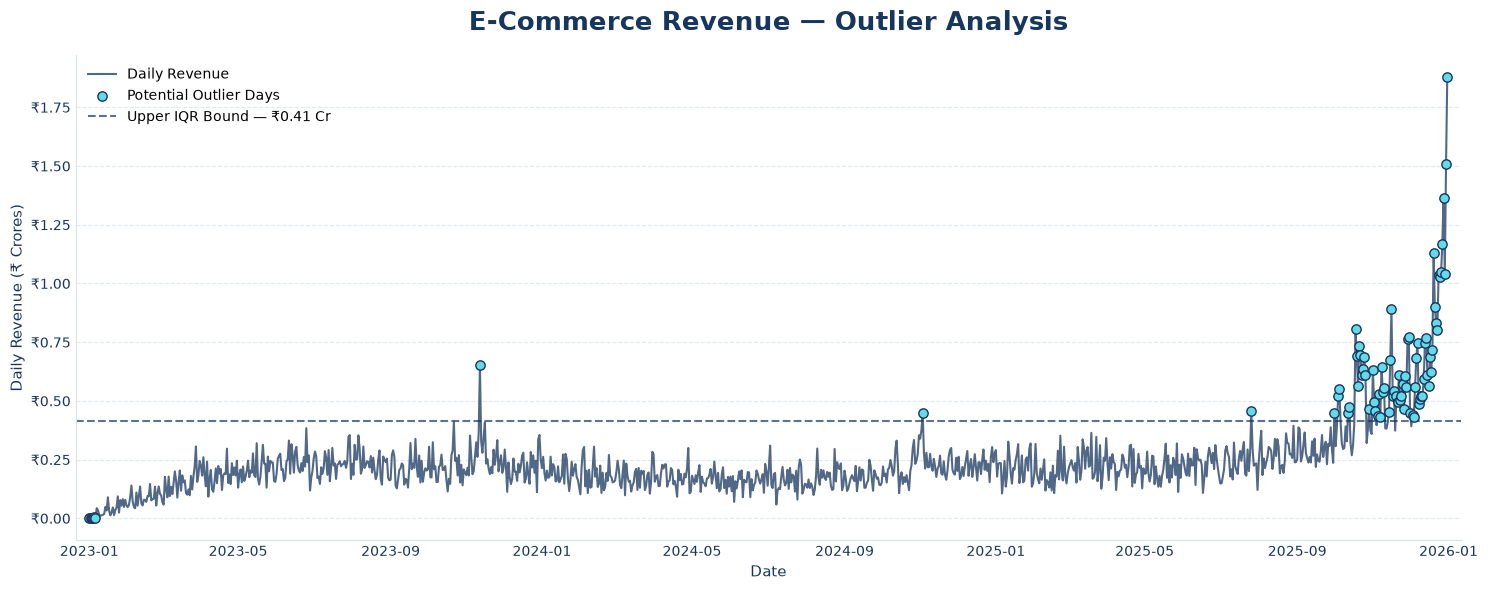

In [25]:
# Revenue Outliers Across the Timeline

from matplotlib.ticker import FuncFormatter

NAVY = "#17365D"
CYAN = "#64D9E8"
GRID = "#D9E2F3"

fig, ax = plt.subplots(figsize=(15, 6))

# Normal daily revenue
ax.plot(
    df["date"],
    df["daily_revenue"] / 1e7,
    color=NAVY,
    linewidth=1.5,
    alpha=0.75,
    label="Daily Revenue"
)

# Outlier days
ax.scatter(
    outliers["date"],
    outliers["daily_revenue"] / 1e7,
    color=CYAN,
    edgecolor=NAVY,
    linewidth=1,
    s=45,
    zorder=3,
    label="Potential Outlier Days"
)

# Upper IQR threshold
ax.axhline(
    upper_bound / 1e7,
    color=NAVY,
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label=f"Upper IQR Bound — ₹{upper_bound / 1e7:.2f} Cr"
)

ax.set_title(
    "E-Commerce Revenue — Outlier Analysis",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

ax.set_xlabel(
    "Date",
    fontsize=11,
    color=NAVY
)

ax.set_ylabel(
    "Daily Revenue (₹ Crores)",
    fontsize=11,
    color=NAVY
)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:.2f}")
)

ax.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis="x", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

ax.legend(
    frameon=False,
    loc="upper left"
)

ax.margins(x=0.01)

plt.tight_layout()
plt.show()

In [26]:
# Revenue Lag Correlation Analysis

df["lag_1"] = df["daily_revenue"].shift(1)
df["lag_7"] = df["daily_revenue"].shift(7)
df["lag_14"] = df["daily_revenue"].shift(14)
df["lag_30"] = df["daily_revenue"].shift(30)

lag_correlations = {
    "Previous Day (Lag 1)": df["daily_revenue"].corr(df["lag_1"]),
    "Previous Week (Lag 7)": df["daily_revenue"].corr(df["lag_7"]),
    "Previous 2 Weeks (Lag 14)": df["daily_revenue"].corr(df["lag_14"]),
    "Previous Month (Lag 30)": df["daily_revenue"].corr(df["lag_30"])
}

print("Revenue Lag Correlations")
print("-" * 40)

for lag, correlation in lag_correlations.items():
    print(f"{lag}: {correlation:.3f}")

Revenue Lag Correlations
----------------------------------------
Previous Day (Lag 1): 0.853
Previous Week (Lag 7): 0.797
Previous 2 Weeks (Lag 14): 0.737
Previous Month (Lag 30): 0.608


In [27]:
# Forecasting Feature Engineering

forecast_df = df.copy()

# Lag features
forecast_df["lag_1"] = forecast_df["daily_revenue"].shift(1)
forecast_df["lag_7"] = forecast_df["daily_revenue"].shift(7)
forecast_df["lag_14"] = forecast_df["daily_revenue"].shift(14)
forecast_df["lag_30"] = forecast_df["daily_revenue"].shift(30)

# Rolling revenue features
forecast_df["rolling_7"] = (
    forecast_df["daily_revenue"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

forecast_df["rolling_30"] = (
    forecast_df["daily_revenue"]
    .shift(1)
    .rolling(window=30)
    .mean()
)

# Calendar features
forecast_df["day_of_week"] = forecast_df["date"].dt.dayofweek
forecast_df["month"] = forecast_df["date"].dt.month

# Remove rows created by lagging
forecast_df = forecast_df.dropna().reset_index(drop=True)

print("Forecasting feature dataset created.")
print(f"Rows: {len(forecast_df)}")
print(f"Columns: {len(forecast_df.columns)}")

print("\nFeatures:")
print(forecast_df.columns.tolist())

print("\nFirst 5 rows:")
display(forecast_df.head())

Forecasting feature dataset created.
Rows: 1066
Columns: 15

Features:
['date', 'daily_revenue', 'daily_orders', 'daily_customers', 'revenue_30d_avg', 'revenue_30d', 'revenue_7d_avg', 'day_of_week', 'month', 'lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_7', 'rolling_30']

First 5 rows:


,date,daily_revenue,daily_orders,daily_customers,revenue_30d_avg,revenue_30d,revenue_7d_avg,day_of_week,month,lag_1,lag_7,lag_14,lag_30,rolling_7,rolling_30
0,2023-01-31,557008.89,25,24,355187.08,10655612.48,602304.97,1,1,790395.34,936915.01,327396.51,34458.27,656577.27,337768.73
1,2023-02-01,477265.45,18,17,371037.77,11131133.20,635327.80,2,2,557008.89,246105.65,129446.20,1744.73,602304.97,355187.08
2,2023-02-02,569333.75,28,28,390005.74,11700172.17,606005.58,3,2,477265.45,774589.26,252911.94,294.78,635327.80,371037.77
3,2023-02-03,912678.26,38,37,419209.92,12576297.62,659012.78,4,2,569333.75,541627.86,464200.02,36552.81,606005.58,390005.74
4,2023-02-04,1399673.79,29,27,463277.55,13898326.48,741638.67,5,2,912678.26,821292.62,137411.56,77644.93,659012.78,419209.92


In [28]:
# Clean Forecasting Dataset

forecast_df = df[[
    "date",
    "daily_revenue"
]].copy()

# Lag features
forecast_df["lag_1"] = forecast_df["daily_revenue"].shift(1)
forecast_df["lag_7"] = forecast_df["daily_revenue"].shift(7)
forecast_df["lag_14"] = forecast_df["daily_revenue"].shift(14)
forecast_df["lag_30"] = forecast_df["daily_revenue"].shift(30)

# Rolling features
# shift(1) ensures today's revenue is NOT used to predict today's revenue
forecast_df["rolling_7"] = (
    forecast_df["daily_revenue"]
    .shift(1)
    .rolling(7)
    .mean()
)

forecast_df["rolling_30"] = (
    forecast_df["daily_revenue"]
    .shift(1)
    .rolling(30)
    .mean()
)

# Calendar features
forecast_df["day_of_week"] = forecast_df["date"].dt.dayofweek
forecast_df["month"] = forecast_df["date"].dt.month

# Remove rows created by lag/rolling operations
forecast_df = (
    forecast_df
    .dropna()
    .reset_index(drop=True)
)

print("Clean forecasting dataset created.")
print(f"Rows: {len(forecast_df)}")
print(f"Columns: {len(forecast_df.columns)}")

print("\nFeatures:")
print(forecast_df.columns.tolist())

print("\nMissing values:")
print(forecast_df.isnull().sum())

Clean forecasting dataset created.
Rows: 1066
Columns: 10

Features:
['date', 'daily_revenue', 'lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_7', 'rolling_30', 'day_of_week', 'month']

Missing values:
date             0
daily_revenue    0
lag_1            0
lag_7            0
lag_14           0
lag_30           0
rolling_7        0
rolling_30       0
day_of_week      0
month            0
dtype: int64


In [29]:
# Time-Based Train/Test Split

split_index = int(len(forecast_df) * 0.80)

train_df = forecast_df.iloc[:split_index].copy()
test_df = forecast_df.iloc[split_index:].copy()

print("Time-Based Train/Test Split")
print("-" * 40)

print(f"Total rows: {len(forecast_df)}")
print(f"Training rows: {len(train_df)}")
print(f"Testing rows: {len(test_df)}")

print("\nTraining period:")
print("Start:", train_df["date"].min())
print("End:", train_df["date"].max())

print("\nTesting period:")
print("Start:", test_df["date"].min())
print("End:", test_df["date"].max())

Time-Based Train/Test Split
----------------------------------------
Total rows: 1066
Training rows: 852
Testing rows: 214

Training period:
Start: 2023-01-31 00:00:00
End: 2025-05-31 00:00:00

Testing period:
Start: 2025-06-01 00:00:00
End: 2025-12-31 00:00:00


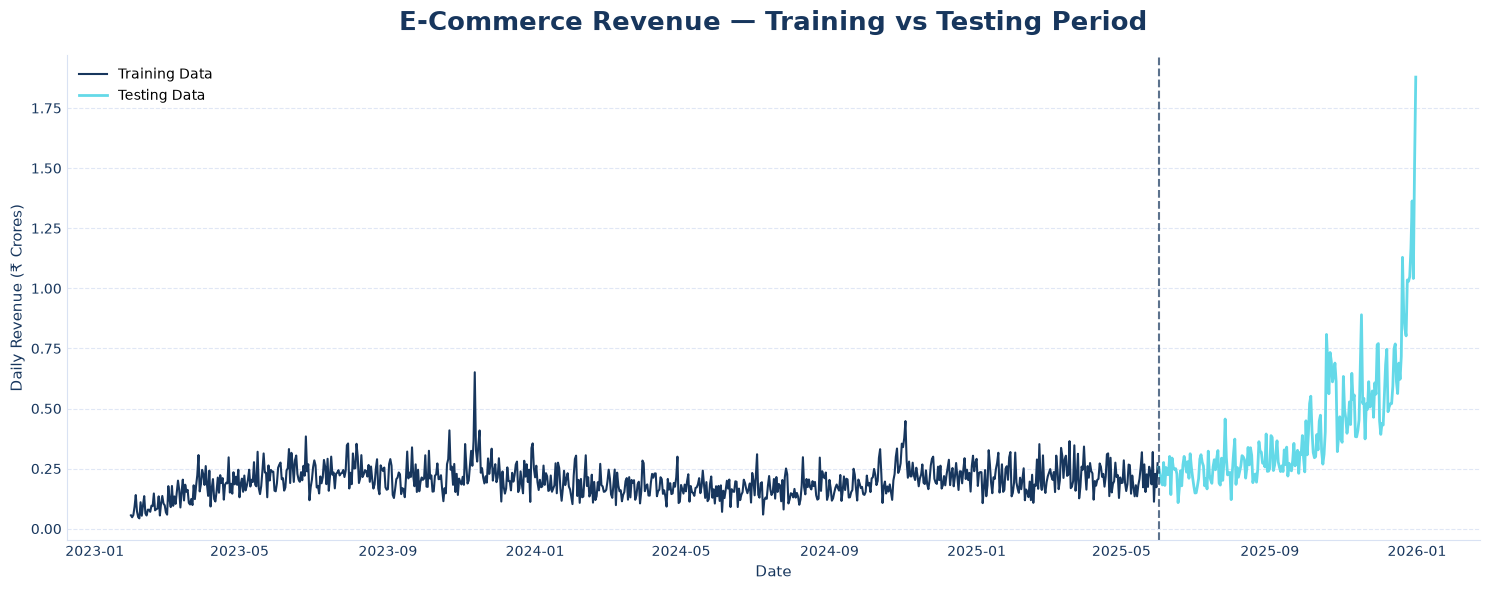

In [30]:
# Visualize Training and Testing Periods

NAVY = "#17365D"
CYAN = "#64D9E8"
GRID = "#D9E2F3"

plt.figure(figsize=(15, 6))

plt.plot(
    train_df["date"],
    train_df["daily_revenue"] / 1e7,
    color=NAVY,
    linewidth=1.5,
    label="Training Data"
)

plt.plot(
    test_df["date"],
    test_df["daily_revenue"] / 1e7,
    color=CYAN,
    linewidth=2,
    label="Testing Data"
)

plt.axvline(
    test_df["date"].min(),
    color=NAVY,
    linestyle="--",
    linewidth=1.5,
    alpha=0.7
)

plt.title(
    "E-Commerce Revenue — Training vs Testing Period",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

plt.xlabel(
    "Date",
    fontsize=11,
    color=NAVY
)

plt.ylabel(
    "Daily Revenue (₹ Crores)",
    fontsize=11,
    color=NAVY
)

plt.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

plt.grid(axis="x", visible=False)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.gca().spines["left"].set_color(GRID)
plt.gca().spines["bottom"].set_color(GRID)

plt.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

plt.legend(
    frameon=False,
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [31]:
# Naive Forecast Baseline
# Tomorrow's revenue = Today's revenue

test_baseline = test_df.copy()

test_baseline["predicted_revenue"] = (
    test_baseline["lag_1"]
)

# Calculate errors
mae = np.mean(
    np.abs(
        test_baseline["daily_revenue"]
        - test_baseline["predicted_revenue"]
    )
)

rmse = np.sqrt(
    np.mean(
        (
            test_baseline["daily_revenue"]
            - test_baseline["predicted_revenue"]
        ) ** 2
    )
)

mape = np.mean(
    np.abs(
        (
            test_baseline["daily_revenue"]
            - test_baseline["predicted_revenue"]
        )
        / test_baseline["daily_revenue"]
    )
) * 100

print("Naive Forecast Baseline")
print("-" * 40)

print(f"MAE  : ₹{mae / 1e7:.4f} Cr")
print(f"RMSE : ₹{rmse / 1e7:.4f} Cr")
print(f"MAPE : {mape:.2f}%")

Naive Forecast Baseline
----------------------------------------
MAE  : ₹0.0829 Cr
RMSE : ₹0.1157 Cr
MAPE : 22.17%


In [33]:
# Prepare Features and Target for ML Forecasting

features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_7",
    "rolling_30",
    "day_of_week",
    "month"
]

target = "daily_revenue"

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("ML Dataset Prepared")
print("-" * 40)

print(f"Training features: {X_train.shape}")
print(f"Training target:   {y_train.shape}")

print(f"Testing features:  {X_test.shape}")
print(f"Testing target:    {y_test.shape}")

print("\nFeatures used:")
for feature in features:
    print("-", feature)

ML Dataset Prepared
----------------------------------------
Training features: (852, 8)
Training target:   (852,)
Testing features:  (214, 8)
Testing target:    (214,)

Features used:
- lag_1
- lag_7
- lag_14
- lag_30
- rolling_7
- rolling_30
- day_of_week
- month


In [34]:
# Random Forest Revenue Forecasting Model

from sklearn.ensemble import RandomForestRegressor

# Create model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(
    X_train,
    y_train
)

# Generate predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully.")
print(f"Predictions generated: {len(rf_predictions)}")

Random Forest model trained successfully.
Predictions generated: 214


In [35]:
# Evaluate Random Forest Forecast

rf_mae = np.mean(
    np.abs(
        y_test - rf_predictions
    )
)

rf_rmse = np.sqrt(
    np.mean(
        (y_test - rf_predictions) ** 2
    )
)

rf_mape = np.mean(
    np.abs(
        (y_test - rf_predictions)
        / y_test
    )
) * 100

print("Random Forest Forecast Performance")
print("-" * 40)

print(f"MAE  : ₹{rf_mae / 1e7:.4f} Cr")
print(f"RMSE : ₹{rf_rmse / 1e7:.4f} Cr")
print(f"MAPE : {rf_mape:.2f}%")

print("\nBaseline MAPE : 22.17%")
print(f"Random Forest MAPE : {rf_mape:.2f}%")

if rf_mape < 22.17:
    print("\n✓ Random Forest beats the naive baseline.")
else:
    print("\n✗ Random Forest does not beat the naive baseline.")

Random Forest Forecast Performance
----------------------------------------
MAE  : ₹0.1600 Cr
RMSE : ₹0.2696 Cr
MAPE : 29.71%

Baseline MAPE : 22.17%
Random Forest MAPE : 29.71%

✗ Random Forest does not beat the naive baseline.


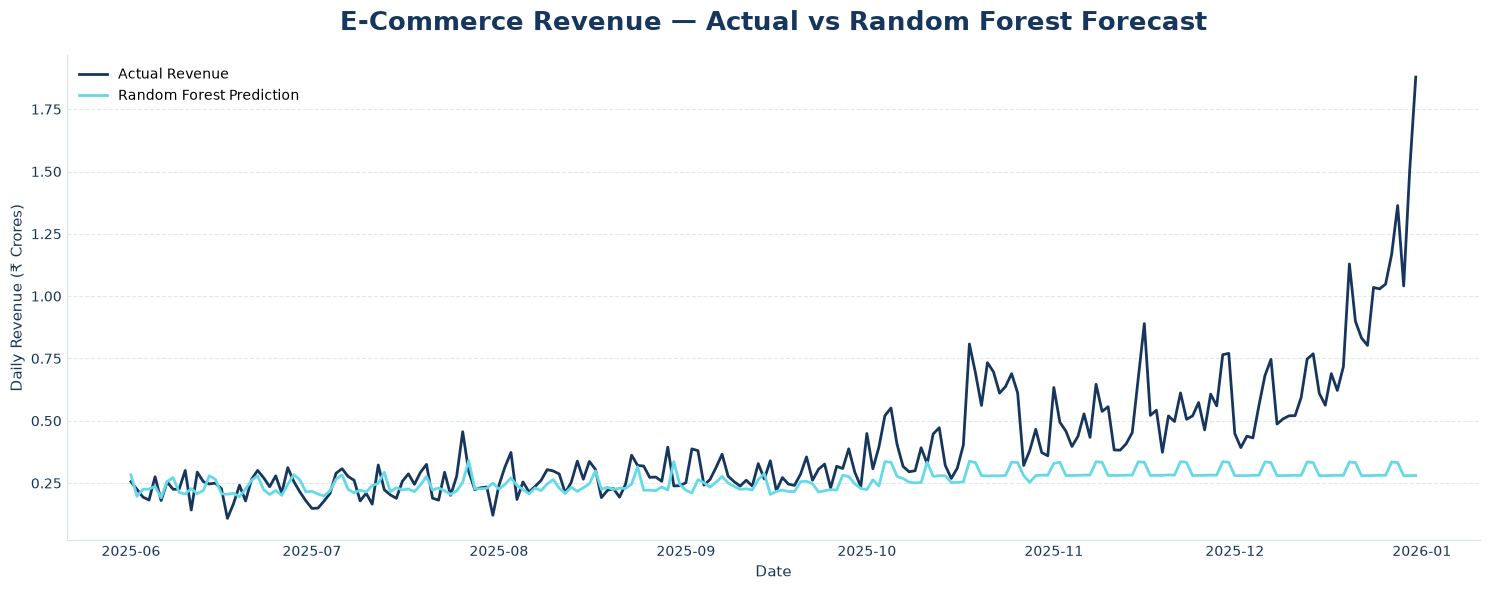

In [36]:
# Actual vs Random Forest Predictions

prediction_df = test_df[
    ["date", "daily_revenue"]
].copy()

prediction_df["rf_prediction"] = rf_predictions

plt.figure(figsize=(15, 6))

plt.plot(
    prediction_df["date"],
    prediction_df["daily_revenue"] / 1e7,
    color="#17365D",
    linewidth=2,
    label="Actual Revenue"
)

plt.plot(
    prediction_df["date"],
    prediction_df["rf_prediction"] / 1e7,
    color="#64D9E8",
    linewidth=2,
    label="Random Forest Prediction"
)

plt.title(
    "E-Commerce Revenue — Actual vs Random Forest Forecast",
    fontsize=19,
    fontweight="bold",
    color="#17365D",
    pad=18
)

plt.xlabel(
    "Date",
    fontsize=11,
    color="#17365D"
)

plt.ylabel(
    "Daily Revenue (₹ Crores)",
    fontsize=11,
    color="#17365D"
)

plt.grid(
    axis="y",
    color="#D9E2F3",
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

plt.grid(axis="x", visible=False)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_color("#D9E2F3")
plt.gca().spines["bottom"].set_color("#D9E2F3")

plt.tick_params(
    axis="both",
    colors="#17365D",
    length=0
)

plt.legend(
    frameon=False,
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [37]:
# Add Time Trend Feature

forecast_df["time_index"] = (
    forecast_df["date"] - forecast_df["date"].min()
).dt.days

print("Time trend feature created.")

print("\nTime Index:")
print(
    forecast_df[
        ["date", "time_index"]
    ].head()
)

print("\nLast records:")
print(
    forecast_df[
        ["date", "time_index"]
    ].tail()
)

Time trend feature created.

Time Index:
        date  time_index
0 2023-01-31           0
1 2023-02-01           1
2 2023-02-02           2
3 2023-02-03           3
4 2023-02-04           4

Last records:
           date  time_index
1061 2025-12-27        1061
1062 2025-12-28        1062
1063 2025-12-29        1063
1064 2025-12-30        1064
1065 2025-12-31        1065


In [38]:
# Prepare Trend-Aware ML Dataset

trend_features = [
    "time_index",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_7",
    "rolling_30",
    "day_of_week",
    "month"
]

X_train_trend = forecast_df[
    forecast_df["date"] <= train_df["date"].max()
][trend_features]

y_train_trend = forecast_df[
    forecast_df["date"] <= train_df["date"].max()
]["daily_revenue"]

X_test_trend = forecast_df[
    forecast_df["date"] > train_df["date"].max()
][trend_features]

y_test_trend = forecast_df[
    forecast_df["date"] > train_df["date"].max()
]["daily_revenue"]

print("Trend-Aware ML Dataset")
print("-" * 40)

print(f"Training features: {X_train_trend.shape}")
print(f"Training target:   {y_train_trend.shape}")

print(f"Testing features:  {X_test_trend.shape}")
print(f"Testing target:    {y_test_trend.shape}")

print("\nFeatures used:")
for feature in trend_features:
    print("-", feature)

Trend-Aware ML Dataset
----------------------------------------
Training features: (852, 9)
Training target:   (852,)
Testing features:  (214, 9)
Testing target:    (214,)

Features used:
- time_index
- lag_1
- lag_7
- lag_14
- lag_30
- rolling_7
- rolling_30
- day_of_week
- month


In [39]:
# Ridge Regression — Trend-Aware Forecasting

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
])

# Train model
ridge_model.fit(
    X_train_trend,
    y_train_trend
)

# Generate predictions
ridge_predictions = ridge_model.predict(
    X_test_trend
)

print("Ridge Regression model trained successfully.")
print(f"Predictions generated: {len(ridge_predictions)}")

Ridge Regression model trained successfully.
Predictions generated: 214


In [40]:
# Evaluate Ridge Regression Forecast

ridge_mae = np.mean(
    np.abs(
        y_test_trend - ridge_predictions
    )
)

ridge_rmse = np.sqrt(
    np.mean(
        (y_test_trend - ridge_predictions) ** 2
    )
)

ridge_mape = np.mean(
    np.abs(
        (y_test_trend - ridge_predictions)
        / y_test_trend
    ) * 100
)

print("Ridge Regression Forecast Performance")
print("-" * 40)

print(f"MAE  : ₹{ridge_mae / 1e7:.4f} Cr")
print(f"RMSE : ₹{ridge_rmse / 1e7:.4f} Cr")
print(f"MAPE : {ridge_mape:.2f}%")

print("\nModel Comparison")
print("-" * 40)
print(f"Naive Baseline MAPE : 22.17%")
print(f"Random Forest MAPE  : {rf_mape:.2f}%")
print(f"Ridge MAPE          : {ridge_mape:.2f}%")

if ridge_mape < 22.17:
    print("\n✓ Ridge Regression beats the naive baseline.")
else:
    print("\n✗ Ridge Regression does not beat the naive baseline.")

Ridge Regression Forecast Performance
----------------------------------------
MAE  : ₹0.0903 Cr
RMSE : ₹0.1543 Cr
MAPE : 18.82%

Model Comparison
----------------------------------------
Naive Baseline MAPE : 22.17%
Random Forest MAPE  : 29.71%
Ridge MAPE          : 18.82%

✓ Ridge Regression beats the naive baseline.


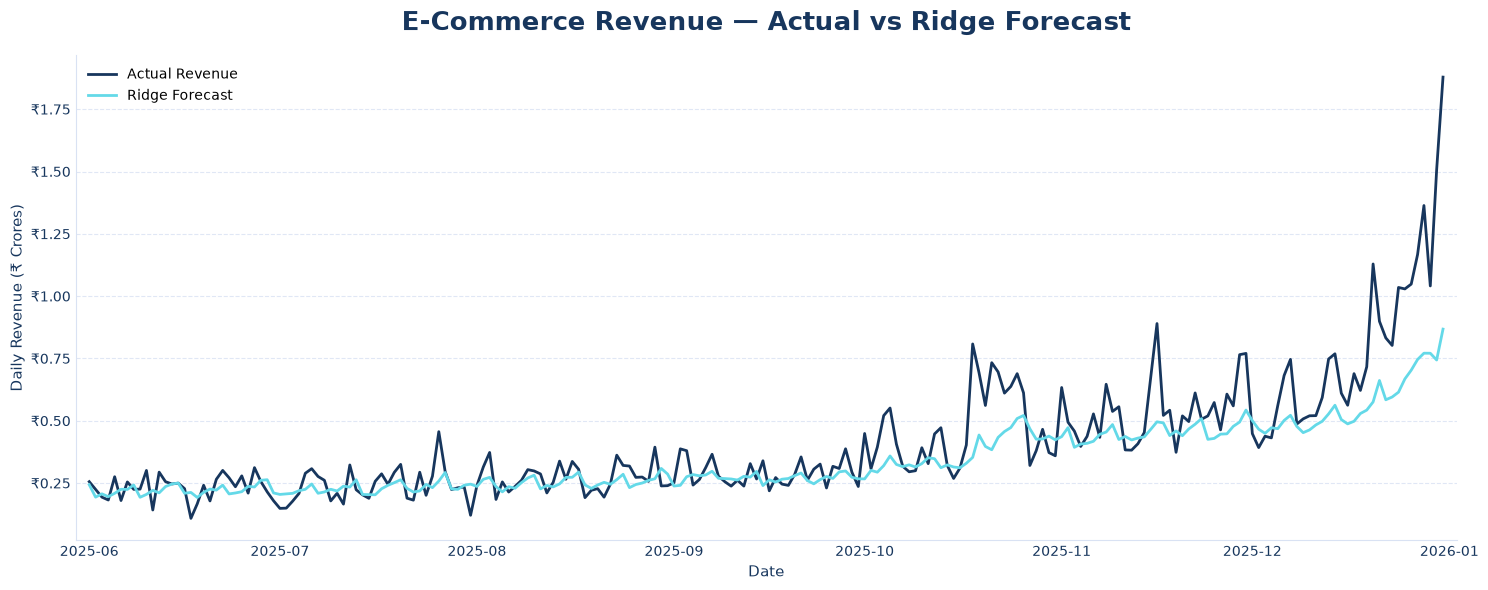

In [41]:
# Actual vs Ridge Regression Forecast

ridge_prediction_df = test_df[
    ["date", "daily_revenue"]
].copy()

ridge_prediction_df["ridge_prediction"] = ridge_predictions

# Power BI-inspired styling
NAVY = "#17365D"
CYAN = "#64D9E8"
GRID = "#D9E2F3"

fig, ax = plt.subplots(figsize=(15, 6))

# Actual revenue
ax.plot(
    ridge_prediction_df["date"],
    ridge_prediction_df["daily_revenue"] / 1e7,
    color=NAVY,
    linewidth=2,
    label="Actual Revenue"
)

# Ridge forecast
ax.plot(
    ridge_prediction_df["date"],
    ridge_prediction_df["ridge_prediction"] / 1e7,
    color=CYAN,
    linewidth=2,
    label="Ridge Forecast"
)

ax.set_title(
    "E-Commerce Revenue — Actual vs Ridge Forecast",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

ax.set_xlabel(
    "Date",
    fontsize=11,
    color=NAVY
)

ax.set_ylabel(
    "Daily Revenue (₹ Crores)",
    fontsize=11,
    color=NAVY
)

# Y-axis in Crores
from matplotlib.ticker import FuncFormatter

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:.2f}")
)

# Grid
ax.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis="x", visible=False)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

ax.legend(
    frameon=False,
    loc="upper left"
)

ax.margins(x=0.01)

plt.tight_layout()
plt.show()

In [42]:
# Ridge Regression — Feature Coefficients

ridge_coefficients = pd.DataFrame({
    "Feature": trend_features,
    "Coefficient": ridge_model.named_steps["ridge"].coef_
})

ridge_coefficients["Absolute_Coefficient"] = (
    ridge_coefficients["Coefficient"].abs()
)

ridge_coefficients = ridge_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

ridge_coefficients

,Feature,Coefficient,Absolute_Coefficient
0,rolling_30,148855.15,148855.15
1,day_of_week,134778.86,134778.86
2,rolling_7,113007.40,113007.40
3,lag_1,84203.05,84203.05
4,month,37246.90,37246.90
5,lag_14,20850.40,20850.40
6,lag_7,20588.86,20588.86
7,lag_30,-19324.49,19324.49
8,time_index,-1467.47,1467.47


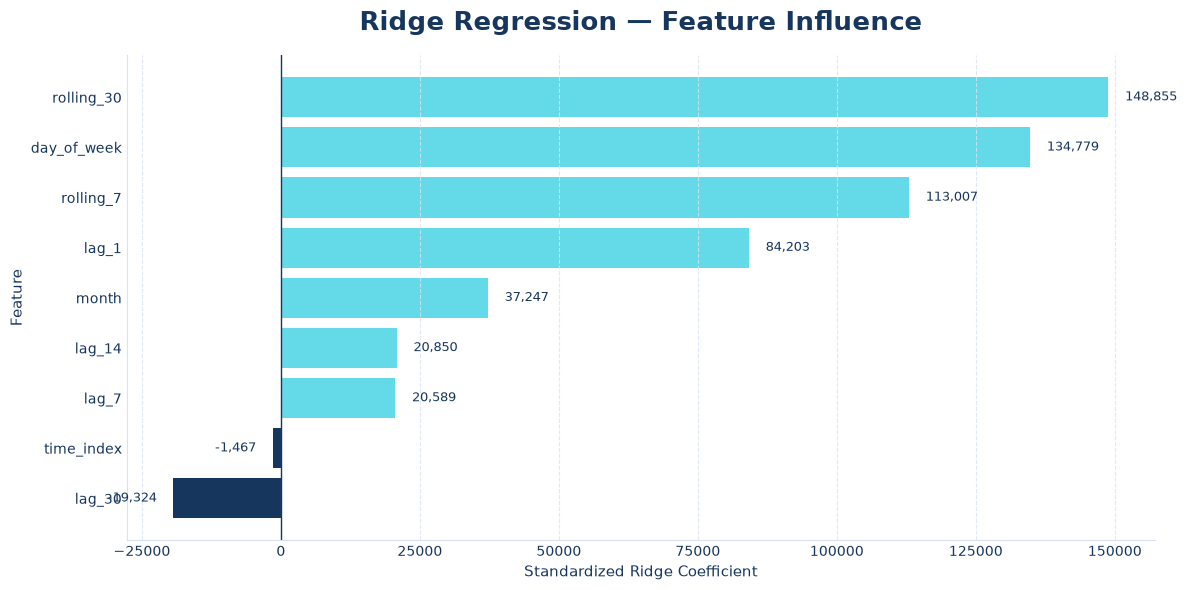

In [43]:
# Ridge Regression — Feature Influence

coef_plot = ridge_coefficients.sort_values(
    "Coefficient",
    ascending=True
)

NAVY = "#17365D"
CYAN = "#64D9E8"
GRID = "#D9E2F3"

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    coef_plot["Feature"],
    coef_plot["Coefficient"],
    color=[
        CYAN if value >= 0 else NAVY
        for value in coef_plot["Coefficient"]
    ]
)

ax.axvline(
    0,
    color=NAVY,
    linewidth=1
)

ax.set_title(
    "Ridge Regression — Feature Influence",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

ax.set_xlabel(
    "Standardized Ridge Coefficient",
    fontsize=11,
    color=NAVY
)

ax.set_ylabel(
    "Feature",
    fontsize=11,
    color=NAVY
)

ax.grid(
    axis="x",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis="y", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

# Add coefficient values
for bar, value in zip(bars, coef_plot["Coefficient"]):
    if value >= 0:
        ax.text(
            value + 3000,
            bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}",
            va="center",
            fontsize=9,
            color=NAVY
        )
    else:
        ax.text(
            value - 3000,
            bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}",
            va="center",
            ha="right",
            fontsize=9,
            color=NAVY
        )

plt.tight_layout()
plt.show()

In [44]:
# Ridge Regression — Residual Analysis

ridge_error_df = test_df[
    ["date", "daily_revenue"]
].copy()

ridge_error_df["predicted_revenue"] = ridge_predictions

ridge_error_df["residual"] = (
    ridge_error_df["daily_revenue"]
    - ridge_error_df["predicted_revenue"]
)

ridge_error_df["absolute_error"] = (
    ridge_error_df["residual"].abs()
)

ridge_error_df["percentage_error"] = (
    ridge_error_df["absolute_error"]
    / ridge_error_df["daily_revenue"]
) * 100

print("Mean Residual:", ridge_error_df["residual"].mean())
print("Mean Absolute Error:", ridge_error_df["absolute_error"].mean())
print("Maximum Absolute Error:", ridge_error_df["absolute_error"].max())

print("\nLargest Prediction Errors:")
display(
    ridge_error_df
    .sort_values("absolute_error", ascending=False)
    .head(10)
)

Mean Residual: 660947.346352766
Mean Absolute Error: 903255.5396983752
Maximum Absolute Error: 10110458.080505833

Largest Prediction Errors:


,date,daily_revenue,predicted_revenue,residual,absolute_error,percentage_error
1065,2025-12-31,18786847.82,8676389.74,10110458.08,10110458.08,53.82
1064,2025-12-30,15071415.15,7437648.60,7633766.55,7633766.55,50.65
1062,2025-12-28,13635132.50,7710461.36,5924671.14,5924671.14,43.45
1054,2025-12-20,11290032.65,5755007.56,5535025.09,5535025.09,49.03
991,2025-10-18,8081277.38,3530283.97,4550993.41,4550993.41,56.32
1061,2025-12-27,11670573.35,7458401.29,4212172.06,4212172.06,36.09
1058,2025-12-24,10347807.11,6147212.54,4200594.57,4200594.57,40.59
1020,2025-11-16,8899566.84,4957861.63,3941705.21,3941705.21,44.29
1059,2025-12-25,10289509.05,6677712.94,3611796.11,3611796.11,35.10
994,2025-10-21,7329944.89,3836242.60,3493702.29,3493702.29,47.66


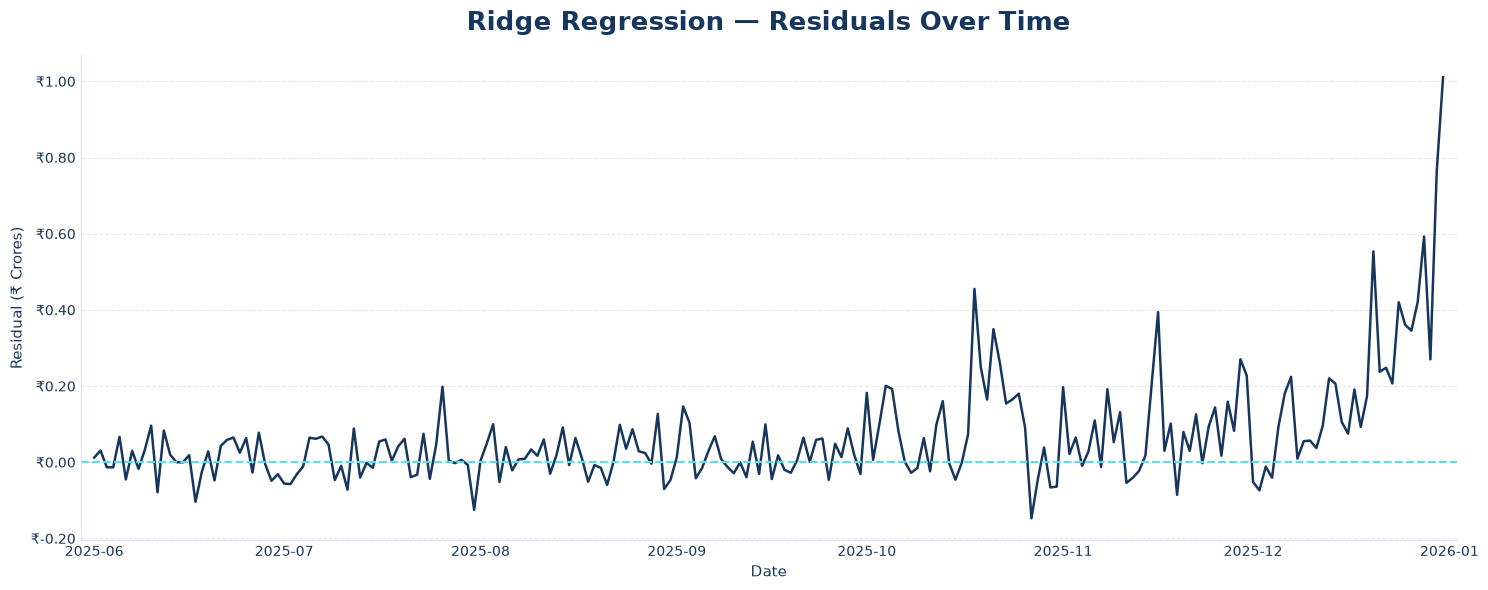

In [45]:
# Ridge Regression — Residuals Over Time

NAVY = "#17365D"
CYAN = "#64D9E8"
GRID = "#D9E2F3"

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    ridge_error_df["date"],
    ridge_error_df["residual"] / 1e7,
    color=NAVY,
    linewidth=1.8
)

ax.axhline(
    0,
    color=CYAN,
    linewidth=1.5,
    linestyle="--"
)

ax.set_title(
    "Ridge Regression — Residuals Over Time",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

ax.set_xlabel(
    "Date",
    fontsize=11,
    color=NAVY
)

ax.set_ylabel(
    "Residual (₹ Crores)",
    fontsize=11,
    color=NAVY
)

from matplotlib.ticker import FuncFormatter

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:.2f}")
)

ax.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis="x", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

ax.margins(x=0.01)

plt.tight_layout()
plt.show()

In [46]:
# Model Performance Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Random Forest",
        "Ridge Regression"
    ],
    "MAE (₹ Crores)": [
        mae / 1e7,
        np.mean(np.abs(y_test - rf_predictions)) / 1e7,
        ridge_mae / 1e7
    ],
    "RMSE (₹ Crores)": [
        rmse / 1e7,
        np.sqrt(np.mean((y_test - rf_predictions) ** 2)) / 1e7,
        ridge_rmse / 1e7
    ],
    "MAPE (%)": [
        mape,
        np.mean(
            np.abs(
                (y_test - rf_predictions) / y_test
            )
        ) * 100,
        ridge_mape
    ]
})

model_comparison = model_comparison.sort_values(
    "MAPE (%)"
).reset_index(drop=True)

model_comparison

,Model,MAE (₹ Crores),RMSE (₹ Crores),MAPE (%)
0,Ridge Regression,0.09,0.15,18.82
1,Naive Baseline,0.08,0.12,22.17
2,Random Forest,0.16,0.27,29.71


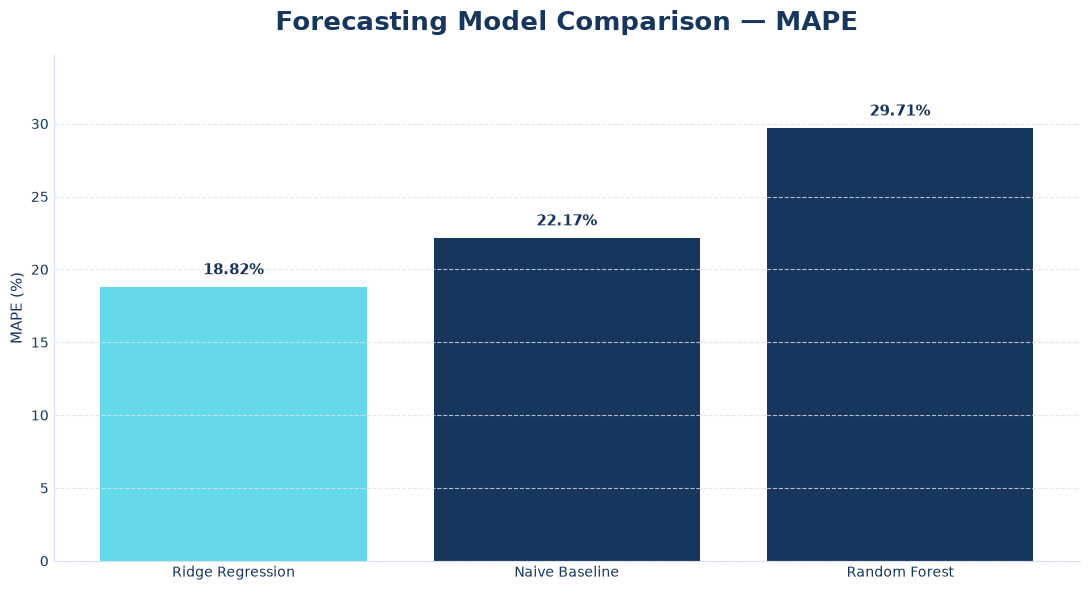

In [47]:
# Model Performance Comparison — Visualization

NAVY = "#17365D"
CYAN = "#64D9E8"
GRID = "#D9E2F3"

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    model_comparison["Model"],
    model_comparison["MAPE (%)"],
    color=[CYAN, NAVY, NAVY]
)

ax.set_title(
    "Forecasting Model Comparison — MAPE",
    fontsize=19,
    fontweight="bold",
    color=NAVY,
    pad=18
)

ax.set_ylabel(
    "MAPE (%)",
    fontsize=11,
    color=NAVY
)

ax.grid(
    axis="y",
    color=GRID,
    linestyle="--",
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis="x", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

ax.tick_params(
    axis="both",
    colors=NAVY,
    length=0
)

for bar, value in zip(
    bars,
    model_comparison["MAPE (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=NAVY
    )

ax.set_ylim(
    0,
    model_comparison["MAPE (%)"].max() + 5
)

plt.tight_layout()
plt.show()

In [48]:
# Final Model Selection Summary

best_model = model_comparison.iloc[0]

print("FINAL MODEL SELECTION")
print("-" * 40)
print(f"Selected Model : {best_model['Model']}")
print(f"MAPE           : {best_model['MAPE (%)']:.2f}%")
print(f"MAE            : ₹{best_model['MAE (₹ Crores)']:.2f} Crores")
print(f"RMSE           : ₹{best_model['RMSE (₹ Crores)']:.2f} Crores")

print("\nReason for Selection:")
print(
    "Ridge Regression achieved the lowest MAPE among the evaluated "
    "forecasting approaches and was therefore selected as the preferred "
    "model for the forecasting pipeline."
)

FINAL MODEL SELECTION
----------------------------------------
Selected Model : Ridge Regression
MAPE           : 18.82%
MAE            : ₹0.09 Crores
RMSE           : ₹0.15 Crores

Reason for Selection:
Ridge Regression achieved the lowest MAPE among the evaluated forecasting approaches and was therefore selected as the preferred model for the forecasting pipeline.


In [49]:
# Final Ridge Model — Train on All Historical Data

X_full = forecast_df[trend_features]
y_full = forecast_df["daily_revenue"]

final_ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
])

final_ridge_model.fit(
    X_full,
    y_full
)

print("Final Ridge model trained successfully.")
print(f"Training rows: {len(X_full)}")
print(f"Features used: {len(trend_features)}")
print(f"Model: Ridge Regression")
print("Training data: All available historical data")

Final Ridge model trained successfully.
Training rows: 1066
Features used: 9
Model: Ridge Regression
Training data: All available historical data


In [50]:
# Prepare Historical Revenue Series for Recursive Forecasting

historical_revenue = (
    forecast_df[["date", "daily_revenue"]]
    .copy()
    .set_index("date")
    .sort_index()
)

last_historical_date = historical_revenue.index.max()

print("Last historical date:", last_historical_date.date())
print("Historical observations:", len(historical_revenue))
print("Latest revenue:", f"₹{historical_revenue['daily_revenue'].iloc[-1]:,.2f}")

Last historical date: 2025-12-31
Historical observations: 1066
Latest revenue: ₹18,786,847.82


In [51]:
# Create Future 30-Day Forecast Dates

future_dates = pd.date_range(
    start=last_historical_date + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

print("Forecast start:", future_dates[0].date())
print("Forecast end:", future_dates[-1].date())
print("Forecast days:", len(future_dates))

Forecast start: 2026-01-01
Forecast end: 2026-01-30
Forecast days: 30


In [52]:
# Recursive 30-Day Revenue Forecast

forecast_history = historical_revenue["daily_revenue"].copy()

forecast_results = []

start_time_index = forecast_df["time_index"].max()

for i, forecast_date in enumerate(future_dates, start=1):

    # Create forecasting features
    lag_1 = forecast_history.iloc[-1]
    lag_7 = forecast_history.iloc[-7]
    lag_14 = forecast_history.iloc[-14]
    lag_30 = forecast_history.iloc[-30]

    rolling_7 = forecast_history.iloc[-7:].mean()
    rolling_30 = forecast_history.iloc[-30:].mean()

    day_of_week = forecast_date.dayofweek
    month = forecast_date.month
    time_index = start_time_index + i

    # Create one-row feature dataframe
    future_features = pd.DataFrame({
        "time_index": [time_index],
        "lag_1": [lag_1],
        "lag_7": [lag_7],
        "lag_14": [lag_14],
        "lag_30": [lag_30],
        "rolling_7": [rolling_7],
        "rolling_30": [rolling_30],
        "day_of_week": [day_of_week],
        "month": [month]
    })

    # Ensure feature order matches training
    future_features = future_features[trend_features]

    # Generate prediction
    predicted_revenue = final_ridge_model.predict(
        future_features
    )[0]

    # Store prediction
    forecast_results.append({
        "date": forecast_date,
        "predicted_revenue": predicted_revenue
    })

    # Add prediction to history for the next recursive step
    forecast_history.loc[forecast_date] = predicted_revenue


forecast_30d = pd.DataFrame(forecast_results)

print("30-day recursive forecast generated successfully.")
print("Forecast rows:", len(forecast_30d))
print("Forecast start:", forecast_30d["date"].min().date())
print("Forecast end:", forecast_30d["date"].max().date())

30-day recursive forecast generated successfully.
Forecast rows: 30
Forecast start: 2026-01-01
Forecast end: 2026-01-30


In [53]:
# Inspect the 30-Day Forecast

forecast_30d["predicted_revenue_crores"] = (
    forecast_30d["predicted_revenue"] / 1e7
)

display(forecast_30d)

,date,predicted_revenue,predicted_revenue_crores
0,2026-01-01,15492645.79,1.55
1,2026-01-02,15096235.57,1.51
2,2026-01-03,15988729.78,1.60
3,2026-01-04,16561935.51,1.66
4,2026-01-05,16250672.26,1.63
5,2026-01-06,16976748.01,1.70
6,2026-01-07,18109611.11,1.81
7,2026-01-08,18311073.20,1.83
8,2026-01-09,18729881.48,1.87
9,2026-01-10,19477800.31,1.95


In [54]:
# 30-Day Forecast — Sanity Check

forecast_start_value = forecast_30d["predicted_revenue"].iloc[0]
forecast_end_value = forecast_30d["predicted_revenue"].iloc[-1]

forecast_total = forecast_30d["predicted_revenue"].sum()
forecast_average = forecast_30d["predicted_revenue"].mean()

forecast_growth = (
    (forecast_end_value - forecast_start_value)
    / forecast_start_value
) * 100

print("30-DAY FORECAST SANITY CHECK")
print("-" * 40)

print(f"Forecast Start Revenue : ₹{forecast_start_value:,.2f}")
print(f"Forecast End Revenue   : ₹{forecast_end_value:,.2f}")
print(f"Forecast Average/Day   : ₹{forecast_average:,.2f}")
print(f"Forecast Total Revenue : ₹{forecast_total:,.2f}")
print(f"Start-to-End Growth    : {forecast_growth:.2f}%")

print("\nHistorical Context")
print("-" * 40)

recent_30_average = historical_revenue["daily_revenue"].tail(30).mean()

print(
    f"Previous 30-Day Average : "
    f"₹{recent_30_average:,.2f}"
)

print(
    f"Forecast 30-Day Average : "
    f"₹{forecast_average:,.2f}"
)

print(
    f"Average Change          : "
    f"{((forecast_average / recent_30_average) - 1) * 100:.2f}%"
)

30-DAY FORECAST SANITY CHECK
----------------------------------------
Forecast Start Revenue : ₹15,492,645.79
Forecast End Revenue   : ₹36,160,147.09
Forecast Average/Day   : ₹23,998,392.23
Forecast Total Revenue : ₹719,951,766.90
Start-to-End Growth    : 133.40%

Historical Context
----------------------------------------
Previous 30-Day Average : ₹8,109,108.49
Forecast 30-Day Average : ₹23,998,392.23
Average Change          : 195.94%


In [55]:
# Improved Forecasting Dataset
# Treat day_of_week and month as categorical features

improved_df = forecast_df.copy()

# Convert seasonal variables to categorical type
improved_df["day_of_week"] = improved_df["day_of_week"].astype(str)
improved_df["month"] = improved_df["month"].astype(str)

print("Improved forecasting dataset created.")
print("Rows:", len(improved_df))
print("Columns:", len(improved_df.columns))

print("\nDay-of-week values:")
print(sorted(improved_df["day_of_week"].unique()))

print("\nMonth values:")
print(sorted(improved_df["month"].unique()))

Improved forecasting dataset created.
Rows: 1066
Columns: 11

Day-of-week values:
['0', '1', '2', '3', '4', '5', '6']

Month values:
['1', '10', '11', '12', '2', '3', '4', '5', '6', '7', '8', '9']


In [56]:
# Improved Model — Time-Based Train/Test Split

split_index = int(len(improved_df) * 0.80)

improved_train_df = improved_df.iloc[:split_index].copy()
improved_test_df = improved_df.iloc[split_index:].copy()

print("IMPROVED MODEL TRAIN/TEST SPLIT")
print("-" * 40)

print(f"Total observations : {len(improved_df)}")
print(f"Training rows      : {len(improved_train_df)}")
print(f"Testing rows       : {len(improved_test_df)}")

print("\nTraining period:")
print(
    improved_train_df["date"].min().date(),
    "to",
    improved_train_df["date"].max().date()
)

print("\nTesting period:")
print(
    improved_test_df["date"].min().date(),
    "to",
    improved_test_df["date"].max().date()
)

IMPROVED MODEL TRAIN/TEST SPLIT
----------------------------------------
Total observations : 1066
Training rows      : 852
Testing rows       : 214

Training period:
2023-01-31 to 2025-05-31

Testing period:
2025-06-01 to 2025-12-31


In [57]:
# Improved Model — Feature Definition

numeric_features = [
    "time_index",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_7",
    "rolling_30"
]

categorical_features = [
    "day_of_week",
    "month"
]

target = "daily_revenue"

X_train_improved = improved_train_df[
    numeric_features + categorical_features
]

y_train_improved = improved_train_df[target]

X_test_improved = improved_test_df[
    numeric_features + categorical_features
]

y_test_improved = improved_test_df[target]

print("IMPROVED MODEL FEATURES")
print("-" * 40)

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTraining shape:", X_train_improved.shape)
print("Testing shape :", X_test_improved.shape)

IMPROVED MODEL FEATURES
----------------------------------------
Numerical features:
['time_index', 'lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_7', 'rolling_30']

Categorical features:
['day_of_week', 'month']

Training shape: (852, 9)
Testing shape : (214, 9)


In [58]:
# Improved Model — Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

print("\nNumerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Preprocessing pipeline created successfully.

Numerical features: 7
Categorical features: 2


In [59]:
# Improved Ridge Regression Model

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

improved_ridge_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "ridge",
        Ridge(alpha=10.0)
    )
])

improved_ridge_model.fit(
    X_train_improved,
    y_train_improved
)

print("Improved Ridge Regression model trained successfully.")
print("Training rows:", len(X_train_improved))
print("Features before encoding:", X_train_improved.shape[1])

Improved Ridge Regression model trained successfully.
Training rows: 852
Features before encoding: 9


In [60]:
# Improved Ridge Regression — Test Predictions & Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate predictions
improved_predictions = improved_ridge_model.predict(
    X_test_improved
)

# Calculate evaluation metrics
improved_mae = mean_absolute_error(
    y_test_improved,
    improved_predictions
)

improved_rmse = np.sqrt(
    mean_squared_error(
        y_test_improved,
        improved_predictions
    )
)

improved_mape = np.mean(
    np.abs(
        (y_test_improved - improved_predictions)
        / y_test_improved
    )
) * 100

print("IMPROVED RIDGE REGRESSION — TEST RESULTS")
print("-" * 50)

print(f"MAE  : ₹{improved_mae:,.2f}")
print(f"RMSE : ₹{improved_rmse:,.2f}")
print(f"MAPE : {improved_mape:.2f}%")

print("\nTest observations:", len(y_test_improved))

IMPROVED RIDGE REGRESSION — TEST RESULTS
--------------------------------------------------
MAE  : ₹931,408.87
RMSE : ₹1,600,399.26
MAPE : 19.08%

Test observations: 214


In [61]:
# Improved Ridge — Train on All Historical Data

X_full_improved = improved_df[
    numeric_features + categorical_features
]

y_full_improved = improved_df[target]

final_improved_ridge_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "ridge",
        Ridge(alpha=10.0)
    )
])

final_improved_ridge_model.fit(
    X_full_improved,
    y_full_improved
)

print("Improved Ridge model trained on all historical data.")
print("Historical rows:", len(X_full_improved))
print("Features before encoding:", X_full_improved.shape[1])

Improved Ridge model trained on all historical data.
Historical rows: 1066
Features before encoding: 9


In [62]:
# Improved Ridge — Prepare Historical Forecast Series

improved_historical_revenue = (
    improved_df[["date", "daily_revenue"]]
    .copy()
    .set_index("date")
    .sort_index()
)

improved_last_historical_date = (
    improved_historical_revenue.index.max()
)

print("HISTORICAL FORECAST SERIES")
print("-" * 40)

print(
    "Last historical date :",
    improved_last_historical_date.date()
)

print(
    "Historical observations :",
    len(improved_historical_revenue)
)

print(
    "Latest daily revenue :",
    f"₹{improved_historical_revenue['daily_revenue'].iloc[-1]:,.2f}"
)

HISTORICAL FORECAST SERIES
----------------------------------------
Last historical date : 2025-12-31
Historical observations : 1066
Latest daily revenue : ₹18,786,847.82


In [63]:
# Improved Ridge — Create Future Forecast Dates

improved_future_dates = pd.date_range(
    start=improved_last_historical_date + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

print("30-DAY FORECAST PERIOD")
print("-" * 40)

print(
    "Forecast start :",
    improved_future_dates[0].date()
)

print(
    "Forecast end   :",
    improved_future_dates[-1].date()
)

print(
    "Forecast days  :",
    len(improved_future_dates)
)

30-DAY FORECAST PERIOD
----------------------------------------
Forecast start : 2026-01-01
Forecast end   : 2026-01-30
Forecast days  : 30


In [64]:
# Improved Ridge — Recursive 30-Day Forecast

improved_forecast_history = (
    improved_historical_revenue["daily_revenue"].copy()
)

improved_forecast_results = []

improved_start_time_index = improved_df["time_index"].max()

for i, forecast_date in enumerate(
    improved_future_dates,
    start=1
):

    # Lag features
    lag_1 = improved_forecast_history.iloc[-1]
    lag_7 = improved_forecast_history.iloc[-7]
    lag_14 = improved_forecast_history.iloc[-14]
    lag_30 = improved_forecast_history.iloc[-30]

    # Rolling features
    rolling_7 = improved_forecast_history.iloc[-7:].mean()
    rolling_30 = improved_forecast_history.iloc[-30:].mean()

    # Calendar features
    day_of_week = str(forecast_date.dayofweek)
    month = str(forecast_date.month)

    # Time trend
    time_index = improved_start_time_index + i

    # Create one future observation
    future_features = pd.DataFrame({
        "time_index": [time_index],
        "lag_1": [lag_1],
        "lag_7": [lag_7],
        "lag_14": [lag_14],
        "lag_30": [lag_30],
        "rolling_7": [rolling_7],
        "rolling_30": [rolling_30],
        "day_of_week": [day_of_week],
        "month": [month]
    })

    # Keep the exact feature order
    future_features = future_features[
        numeric_features + categorical_features
    ]

    # Predict
    predicted_revenue = (
        final_improved_ridge_model
        .predict(future_features)[0]
    )

    # Store result
    improved_forecast_results.append({
        "date": forecast_date,
        "predicted_revenue": predicted_revenue
    })

    # Add prediction to history for recursive forecasting
    improved_forecast_history.loc[
        forecast_date
    ] = predicted_revenue

improved_forecast_30d = pd.DataFrame(
    improved_forecast_results
)

print("IMPROVED 30-DAY FORECAST GENERATED")
print("-" * 50)

print(
    "Forecast rows :",
    len(improved_forecast_30d)
)

print(
    "Forecast start :",
    improved_forecast_30d["date"].min().date()
)

print(
    "Forecast end   :",
    improved_forecast_30d["date"].max().date()
)

IMPROVED 30-DAY FORECAST GENERATED
--------------------------------------------------
Forecast rows : 30
Forecast start : 2026-01-01
Forecast end   : 2026-01-30


In [65]:
# Improved Ridge — Inspect 30-Day Forecast

print("IMPROVED 30-DAY FORECAST")
print("-" * 60)

display(
    improved_forecast_30d.assign(
        predicted_revenue_crores=
        improved_forecast_30d["predicted_revenue"] / 10_000_000
    )[[
        "date",
        "predicted_revenue",
        "predicted_revenue_crores"
    ]].round(2)
)

IMPROVED 30-DAY FORECAST
------------------------------------------------------------


C:\Users\samee\AppData\Local\Temp\ipykernel_70072\1507555557.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].round(2)


,date,predicted_revenue,predicted_revenue_crores
0,2026-01-01,15351955.87,1.54
1,2026-01-02,14807606.88,1.48
2,2026-01-03,15910328.89,1.59
3,2026-01-04,16272639.28,1.63
4,2026-01-05,16037976.46,1.60
5,2026-01-06,16686412.02,1.67
6,2026-01-07,17604694.82,1.76
7,2026-01-08,17725435.00,1.77
8,2026-01-09,18047823.92,1.80
9,2026-01-10,19114565.68,1.91


In [66]:
# Improved Ridge — Inspect 30-Day Forecast

forecast_display = improved_forecast_30d.copy()

forecast_display["predicted_revenue_crores"] = (
    forecast_display["predicted_revenue"] / 10_000_000
)

forecast_display["predicted_revenue"] = (
    forecast_display["predicted_revenue"].round(2)
)

forecast_display["predicted_revenue_crores"] = (
    forecast_display["predicted_revenue_crores"].round(2)
)

print("IMPROVED 30-DAY FORECAST")
print("-" * 60)

display(forecast_display)

IMPROVED 30-DAY FORECAST
------------------------------------------------------------


,date,predicted_revenue,predicted_revenue_crores
0,2026-01-01,15351955.87,1.54
1,2026-01-02,14807606.88,1.48
2,2026-01-03,15910328.89,1.59
3,2026-01-04,16272639.28,1.63
4,2026-01-05,16037976.46,1.60
5,2026-01-06,16686412.02,1.67
6,2026-01-07,17604694.82,1.76
7,2026-01-08,17725435.00,1.77
8,2026-01-09,18047823.92,1.80
9,2026-01-10,19114565.68,1.91


In [67]:
# Ridge Model Without Explicit Time Trend

no_trend_numeric_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_7",
    "rolling_30"
]

no_trend_categorical_features = [
    "day_of_week",
    "month"
]

X_train_no_trend = improved_train_df[
    no_trend_numeric_features + no_trend_categorical_features
]

X_test_no_trend = improved_test_df[
    no_trend_numeric_features + no_trend_categorical_features
]

y_train_no_trend = improved_train_df[target]
y_test_no_trend = improved_test_df[target]

print("RIDGE WITHOUT TIME TREND")
print("-" * 40)

print("Numerical features:", no_trend_numeric_features)
print("Categorical features:", no_trend_categorical_features)

print("\nTraining shape:", X_train_no_trend.shape)
print("Testing shape :", X_test_no_trend.shape)

RIDGE WITHOUT TIME TREND
----------------------------------------
Numerical features: ['lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_7', 'rolling_30']
Categorical features: ['day_of_week', 'month']

Training shape: (852, 8)
Testing shape : (214, 8)


In [68]:
# Ridge Without Time Trend — Preprocessing Pipeline

no_trend_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            no_trend_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            no_trend_categorical_features
        )
    ]
)

print("No-trend preprocessing pipeline created successfully.")

print(
    "Numerical features:",
    len(no_trend_numeric_features)
)

print(
    "Categorical features:",
    len(no_trend_categorical_features)
)


No-trend preprocessing pipeline created successfully.
Numerical features: 6
Categorical features: 2


In [69]:
# No-Trend Ridge Regression Model

no_trend_ridge_model = Pipeline([
    (
        "preprocessor",
        no_trend_preprocessor
    ),
    (
        "ridge",
        Ridge(alpha=10.0)
    )
])

no_trend_ridge_model.fit(
    X_train_no_trend,
    y_train_no_trend
)

print("No-trend Ridge Regression model trained successfully.")
print("Training rows:", len(X_train_no_trend))
print("Features before encoding:", X_train_no_trend.shape[1])

No-trend Ridge Regression model trained successfully.
Training rows: 852
Features before encoding: 8


In [70]:
# Evaluate No-Trend Ridge Regression

no_trend_predictions = no_trend_ridge_model.predict(
    X_test_no_trend
)

no_trend_mae = np.mean(
    np.abs(y_test_no_trend - no_trend_predictions)
)

no_trend_rmse = np.sqrt(
    np.mean(
        (y_test_no_trend - no_trend_predictions) ** 2
    )
)

no_trend_mape = np.mean(
    np.abs(
        (y_test_no_trend - no_trend_predictions)
        / y_test_no_trend
    )
) * 100

print("NO-TREND RIDGE REGRESSION")
print("-" * 40)

print(f"MAE  : ₹{no_trend_mae:,.2f}")
print(f"RMSE : ₹{no_trend_rmse:,.2f}")
print(f"MAPE : {no_trend_mape:.2f}%")
print(f"Test observations: {len(y_test_no_trend)}")

NO-TREND RIDGE REGRESSION
----------------------------------------
MAE  : ₹930,601.21
RMSE : ₹1,599,705.18
MAPE : 19.07%
Test observations: 214


In [71]:
# Final Model Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Random Forest",
        "Original Ridge",
        "Improved Ridge",
        "No-Trend Ridge"
    ],
    "MAE": [
        mae,
        rf_mae,
        ridge_mae,
        improved_mae,
        no_trend_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse,
        ridge_rmse,
        improved_rmse,
        no_trend_rmse
    ],
    "MAPE": [
        mape,
        rf_mape,
        ridge_mape,
        improved_mape,
        no_trend_mape
    ]
})

model_comparison["MAE_Crores"] = (
    model_comparison["MAE"] / 10_000_000
)

model_comparison["RMSE_Crores"] = (
    model_comparison["RMSE"] / 10_000_000
)

model_comparison = model_comparison.sort_values(
    "MAPE"
).reset_index(drop=True)

display(model_comparison.round(2))

,Model,MAE,RMSE,MAPE,MAE_Crores,RMSE_Crores
0,Original Ridge,903255.54,1543285.08,18.82,0.09,0.15
1,No-Trend Ridge,930601.21,1599705.18,19.07,0.09,0.16
2,Improved Ridge,931408.87,1600399.26,19.08,0.09,0.16
3,Naive Baseline,828900.44,1156617.39,22.17,0.08,0.12
4,Random Forest,1600174.56,2695558.89,29.71,0.16,0.27


In [72]:
# Prepare Final Forecast Evaluation Summary

best_model = model_comparison.iloc[0]["Model"]
best_mape = model_comparison.iloc[0]["MAPE"]

print("FINAL MODEL EVALUATION")
print("-" * 40)
print(f"Selected model : {best_model}")
print(f"MAPE           : {best_mape:.2f}%")
print()
print("Important validation note:")
print("The model is evaluated using a time-based test set.")
print("The 30-day recursive forecast is treated separately")
print("because recursive predictions can accumulate errors.")

FINAL MODEL EVALUATION
----------------------------------------
Selected model : Original Ridge
MAPE           : 18.82%

Important validation note:
The model is evaluated using a time-based test set.
The 30-day recursive forecast is treated separately
because recursive predictions can accumulate errors.


In [73]:
# 30-Day Forecast Stability Check

forecast_start = improved_forecast_30d["predicted_revenue"].iloc[0]
forecast_end = improved_forecast_30d["predicted_revenue"].iloc[-1]
forecast_average = improved_forecast_30d["predicted_revenue"].mean()
forecast_total = improved_forecast_30d["predicted_revenue"].sum()

forecast_growth = (
    (forecast_end - forecast_start)
    / forecast_start
) * 100

previous_30d_average = (
    historical_revenue["daily_revenue"]
    .tail(30)
    .mean()
)

average_change = (
    (forecast_average - previous_30d_average)
    / previous_30d_average
) * 100

print("30-DAY FORECAST STABILITY CHECK")
print("-" * 45)

print(f"Forecast start       : ₹{forecast_start:,.2f}")
print(f"Forecast end         : ₹{forecast_end:,.2f}")
print(f"Forecast average/day : ₹{forecast_average:,.2f}")
print(f"Forecast total       : ₹{forecast_total:,.2f}")
print(f"Start-to-end growth  : {forecast_growth:.2f}%")
print(f"Previous 30-day avg  : ₹{previous_30d_average:,.2f}")
print(f"Average change       : {average_change:.2f}%")

30-DAY FORECAST STABILITY CHECK
---------------------------------------------
Forecast start       : ₹15,351,955.87
Forecast end         : ₹34,060,139.26
Forecast average/day : ₹23,141,668.69
Forecast total       : ₹694,250,060.59
Start-to-end growth  : 121.86%
Previous 30-day avg  : ₹8,109,108.49
Average change       : 185.38%


In [74]:
# Create a Direct Forecast Dataset

direct_df = forecast_df.copy()

# Create future target: revenue 7 days ahead
direct_df["target_7d"] = direct_df["daily_revenue"].shift(-7)

direct_df = direct_df.dropna().reset_index(drop=True)

print("DIRECT FORECAST DATASET")
print("-" * 40)
print("Rows:", len(direct_df))
print("Columns:", len(direct_df.columns))
print("Target: Revenue 7 days ahead")
print("Missing values:", direct_df.isna().sum().sum())

DIRECT FORECAST DATASET
----------------------------------------
Rows: 1059
Columns: 12
Target: Revenue 7 days ahead
Missing values: 0


In [75]:
# Prepare Direct 7-Day Forecast Train/Test Split

direct_split_index = int(len(direct_df) * 0.80)

direct_train_df = direct_df.iloc[:direct_split_index].copy()
direct_test_df = direct_df.iloc[direct_split_index:].copy()

print("DIRECT 7-DAY FORECAST SPLIT")
print("-" * 40)

print("Total rows :", len(direct_df))
print("Train rows :", len(direct_train_df))
print("Test rows  :", len(direct_test_df))

print()
print("Training period:")
print(direct_train_df["date"].min(), "to", direct_train_df["date"].max())

print()
print("Testing period:")
print(direct_test_df["date"].min(), "to", direct_test_df["date"].max())

DIRECT 7-DAY FORECAST SPLIT
----------------------------------------
Total rows : 1059
Train rows : 847
Test rows  : 212

Training period:
2023-01-31 00:00:00 to 2025-05-26 00:00:00

Testing period:
2025-05-27 00:00:00 to 2025-12-24 00:00:00


In [76]:
# Prepare Features for Direct 7-Day Forecast

direct_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_7",
    "rolling_30",
    "day_of_week",
    "month"
]

direct_target = "target_7d"

X_train_direct = direct_train_df[direct_features]
y_train_direct = direct_train_df[direct_target]

X_test_direct = direct_test_df[direct_features]
y_test_direct = direct_test_df[direct_target]

print("DIRECT 7-DAY FORECAST FEATURES")
print("-" * 40)

print("Training features:", X_train_direct.shape)
print("Testing features :", X_test_direct.shape)
print("Target variable  :", direct_target)
print("Missing values   :", X_train_direct.isna().sum().sum() + X_test_direct.isna().sum().sum())


DIRECT 7-DAY FORECAST FEATURES
----------------------------------------
Training features: (847, 8)
Testing features : (212, 8)
Target variable  : target_7d
Missing values   : 0


In [77]:
# Direct 7-Day Ridge Regression Model

direct_ridge_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "ridge",
        Ridge(alpha=10.0)
    )
])

direct_ridge_model.fit(
    X_train_direct,
    y_train_direct
)

print("Direct 7-Day Ridge Regression model trained successfully.")
print("Training rows:", len(X_train_direct))
print("Features:", X_train_direct.shape[1])

Direct 7-Day Ridge Regression model trained successfully.
Training rows: 847
Features: 8


In [78]:
# Evaluate Direct 7-Day Ridge Regression

direct_predictions = direct_ridge_model.predict(
    X_test_direct
)

direct_mae = np.mean(
    np.abs(y_test_direct - direct_predictions)
)

direct_rmse = np.sqrt(
    np.mean(
        (y_test_direct - direct_predictions) ** 2
    )
)

direct_mape = np.mean(
    np.abs(
        (y_test_direct - direct_predictions)
        / y_test_direct
    )
) * 100

print("DIRECT 7-DAY RIDGE REGRESSION")
print("-" * 40)

print(f"MAE  : ₹{direct_mae:,.2f}")
print(f"RMSE : ₹{direct_rmse:,.2f}")
print(f"MAPE : {direct_mape:.2f}%")
print(f"Test observations: {len(y_test_direct)}")

DIRECT 7-DAY RIDGE REGRESSION
----------------------------------------
MAE  : ₹1,223,231.77
RMSE : ₹2,157,727.71
MAPE : 22.88%
Test observations: 212


In [79]:
# Compare Direct 7-Day Ridge with All Models

final_model_comparison = pd.DataFrame({
    "Model": [
        "Original Ridge",
        "No-Trend Ridge",
        "Improved Ridge",
        "Naive Baseline",
        "Random Forest",
        "Direct 7-Day Ridge"
    ],
    "MAE": [
        ridge_mae,
        no_trend_mae,
        improved_mae,
        mae,
        rf_mae,
        direct_mae
    ],
    "RMSE": [
        ridge_rmse,
        no_trend_rmse,
        improved_rmse,
        rmse,
        rf_rmse,
        direct_rmse
    ],
    "MAPE": [
        ridge_mape,
        no_trend_mape,
        improved_mape,
        mape,
        rf_mape,
        direct_mape
    ]
})

final_model_comparison["MAE_Crores"] = (
    final_model_comparison["MAE"] / 10_000_000
)

final_model_comparison["RMSE_Crores"] = (
    final_model_comparison["RMSE"] / 10_000_000
)

final_model_comparison = final_model_comparison.sort_values(
    "MAPE"
).reset_index(drop=True)

display(final_model_comparison.round(2))

,Model,MAE,RMSE,MAPE,MAE_Crores,RMSE_Crores
0,Original Ridge,903255.54,1543285.08,18.82,0.09,0.15
1,No-Trend Ridge,930601.21,1599705.18,19.07,0.09,0.16
2,Improved Ridge,931408.87,1600399.26,19.08,0.09,0.16
3,Naive Baseline,828900.44,1156617.39,22.17,0.08,0.12
4,Direct 7-Day Ridge,1223231.77,2157727.71,22.88,0.12,0.22
5,Random Forest,1600174.56,2695558.89,29.71,0.16,0.27


In [80]:
# Final Ridge Residual Analysis

final_residual_df = pd.DataFrame({
    "date": test_df["date"].values,
    "actual_revenue": y_test.values,
    "predicted_revenue": ridge_predictions
})

final_residual_df["residual"] = (
    final_residual_df["actual_revenue"]
    - final_residual_df["predicted_revenue"]
)

final_residual_df["absolute_error"] = (
    final_residual_df["residual"].abs()
)

final_residual_df["percentage_error"] = (
    final_residual_df["absolute_error"]
    / final_residual_df["actual_revenue"]
) * 100

print("FINAL RIDGE RESIDUAL ANALYSIS")
print("-" * 40)

print(
    f"Mean residual : "
    f"₹{final_residual_df['residual'].mean():,.2f}"
)

print(
    f"Mean absolute error : "
    f"₹{final_residual_df['absolute_error'].mean():,.2f}"
)

print(
    f"Maximum absolute error : "
    f"₹{final_residual_df['absolute_error'].max():,.2f}"
)

print()
print("Largest prediction errors:")

display(
    final_residual_df
    .sort_values("absolute_error", ascending=False)
    .head(10)
)

FINAL RIDGE RESIDUAL ANALYSIS
----------------------------------------
Mean residual : ₹660,947.35
Mean absolute error : ₹903,255.54
Maximum absolute error : ₹10,110,458.08

Largest prediction errors:


,date,actual_revenue,predicted_revenue,residual,absolute_error,percentage_error
213,2025-12-31,18786847.82,8676389.74,10110458.08,10110458.08,53.82
212,2025-12-30,15071415.15,7437648.60,7633766.55,7633766.55,50.65
210,2025-12-28,13635132.50,7710461.36,5924671.14,5924671.14,43.45
202,2025-12-20,11290032.65,5755007.56,5535025.09,5535025.09,49.03
139,2025-10-18,8081277.38,3530283.97,4550993.41,4550993.41,56.32
209,2025-12-27,11670573.35,7458401.29,4212172.06,4212172.06,36.09
206,2025-12-24,10347807.11,6147212.54,4200594.57,4200594.57,40.59
168,2025-11-16,8899566.84,4957861.63,3941705.21,3941705.21,44.29
207,2025-12-25,10289509.05,6677712.94,3611796.11,3611796.11,35.10
142,2025-10-21,7329944.89,3836242.60,3493702.29,3493702.29,47.66


In [81]:
# Final ML Forecasting Conclusion

print("FINAL ML FORECASTING CONCLUSION")
print("=" * 50)

print()
print("Selected Model:")
print("Ridge Regression")

print()
print("Best Test MAPE:")
print(f"{ridge_mape:.2f}%")

print()
print("Test MAE:")
print(f"₹{ridge_mae:,.2f}")

print()
print("Test RMSE:")
print(f"₹{ridge_rmse:,.2f}")

print()
print("Key Finding:")
print(
    "Ridge Regression achieved the lowest MAPE among "
    "all evaluated forecasting approaches."
)

print()
print("Limitation:")
print(
    "Residual analysis showed systematic underprediction "
    "during high-revenue periods, particularly in Q4 2025."
)

print()
print("Forecasting Decision:")
print(
    "The model is suitable for demonstrating short-term "
    "revenue forecasting capability, but the recursive "
    "30-day forecast should not be treated as a highly "
    "reliable long-horizon business forecast."
)

print()
print("ML forecasting experimentation completed successfully.")

FINAL ML FORECASTING CONCLUSION

Selected Model:
Ridge Regression

Best Test MAPE:
18.82%

Test MAE:
₹903,255.54

Test RMSE:
₹1,543,285.08

Key Finding:
Ridge Regression achieved the lowest MAPE among all evaluated forecasting approaches.

Limitation:
Residual analysis showed systematic underprediction during high-revenue periods, particularly in Q4 2025.

Forecasting Decision:
The model is suitable for demonstrating short-term revenue forecasting capability, but the recursive 30-day forecast should not be treated as a highly reliable long-horizon business forecast.

ML forecasting experimentation completed successfully.
